In [7]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

from sklearn.model_selection import train_test_split
import pandas as pd
import os

In [9]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

rows = []

DATASET_PATH = r"C:\Users\Lenovo\Desktop\KCGI Academics\Academics\Masters_Project\teaLeafBD_fastCrop_merged" 

class_names = sorted([
    d for d in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, d))
])

label2idx = {c:i for i,c in enumerate(class_names)}

for c in class_names:
    cdir = os.path.join(DATASET_PATH, c)

    for fn in os.listdir(cdir):
        if fn.lower().endswith(IMG_EXT):
            rows.append({
                "path": os.path.join(cdir, fn),
                "label": label2idx[c]
            })

df = pd.DataFrame(rows)

print(df.head())

                                                path  label
0  C:\Users\Lenovo\Desktop\KCGI Academics\Academi...      0
1  C:\Users\Lenovo\Desktop\KCGI Academics\Academi...      0
2  C:\Users\Lenovo\Desktop\KCGI Academics\Academi...      0
3  C:\Users\Lenovo\Desktop\KCGI Academics\Academi...      0
4  C:\Users\Lenovo\Desktop\KCGI Academics\Academi...      0


In [79]:
print(class_names)
print(label2idx)

['Tea algal leaf spot', 'Brown Blight', 'Gray Blight', 'Helopeltis', 'Red spider', 'Green mirid bug', 'Healthy leaf']
{'1. Tea algal leaf spot': 0, '2. Brown Blight': 1, '3. Gray Blight': 2, '4. Helopeltis': 3, '5. Red spider': 4, '6. Green mirid bug': 5, '7. Healthy leaf': 6}


In [31]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

In [33]:
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

In [35]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(img, tf.float32)

    return img, label

In [37]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
])

In [39]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_df["path"].values, train_df["label"].values)
)
val_ds = tf.data.Dataset.from_tensor_slices(
    (val_df["path"].values, val_df["label"].values)
)
test_ds = tf.data.Dataset.from_tensor_slices(
    (test_df["path"].values, test_df["label"].values)
)

In [41]:
train_ds = train_ds.map(load_image, num_parallel_calls=AUTOTUNE)
val_ds = val_ds.map(load_image, num_parallel_calls=AUTOTUNE)
test_ds = test_ds.map(load_image, num_parallel_calls=AUTOTUNE)

In [43]:
train_ds = train_ds.map(
    lambda x, y: (data_augmentation(x, training=True), y),
    num_parallel_calls=AUTOTUNE
)

In [44]:
train_ds = train_ds.map(
    lambda x, y: (preprocess_input(x), y),
    num_parallel_calls=AUTOTUNE
)

val_ds = val_ds.map(
    lambda x, y: (preprocess_input(x), y),
    num_parallel_calls=AUTOTUNE
)

test_ds = test_ds.map(
    lambda x, y: (preprocess_input(x), y),
    num_parallel_calls=AUTOTUNE
)

In [47]:
train_ds = train_ds.shuffle(1000).batch(BATCH_SIZE).prefetch(AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

In [49]:
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = True

In [51]:
inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = base_model(inputs, training=True)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.4)(x)

outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

model = models.Model(inputs, outputs)

In [53]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=3e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [55]:
callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        "best_resnet50.keras",
        monitor="val_accuracy",
        save_best_only=True
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=5,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2
    )
]

In [57]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20
115/115 [==============================] - 1457s 12s/step - loss: 0.6705 - accuracy: 0.7695 - val_loss: 0.4071 - val_accuracy: 0.8529 - lr: 3.0000e-04
Epoch 2/20
115/115 [==============================] - 1402s 12s/step - loss: 0.3884 - accuracy: 0.8687 - val_loss: 0.3196 - val_accuracy: 0.8875 - lr: 3.0000e-04
Epoch 3/20
115/115 [==============================] - 1402s 12s/step - loss: 0.2974 - accuracy: 0.9005 - val_loss: 0.2821 - val_accuracy: 0.9079 - lr: 3.0000e-04
Epoch 4/20
115/115 [==============================] - 1490s 13s/step - loss: 0.2513 - accuracy: 0.9137 - val_loss: 0.2583 - val_accuracy: 0.9118 - lr: 3.0000e-04
Epoch 5/20
115/115 [==============================] - 1514s 13s/step - loss: 0.2538 - accuracy: 0.9104 - val_loss: 0.2814 - val_accuracy: 0.9054 - lr: 3.0000e-04
Epoch 6/20
115/115 [==============================] - 1528s 13s/step - loss: 0.2077 - accuracy: 0.9282 - val_loss: 0.2369 - val_accuracy: 0.9066 - lr: 3.0000e-04
Epoch 7/20
115/115 [========

In [59]:
test_loss, test_acc = model.evaluate(test_ds)

print("Test Accuracy:", test_acc)

25/25 [==============================] - 95s 4s/step - loss: 0.2225 - accuracy: 0.9386
Test Accuracy: 0.9386188983917236


In [65]:
best_model = tf.keras.models.load_model(
    "best_resnet50.keras"
)

In [67]:
test_loss, test_acc = best_model.evaluate(test_ds)

print("Test Accuracy:", test_acc)

25/25 [==============================] - 99s 4s/step - loss: 0.2225 - accuracy: 0.9386
Test Accuracy: 0.9386188983917236


In [69]:
best_model.save("final_resnet50_tealeaf_94.keras")

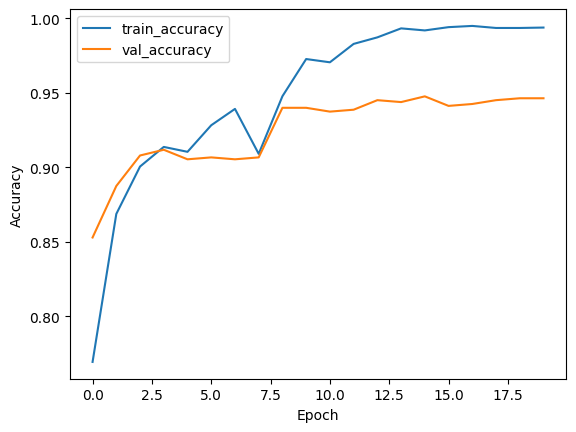

In [73]:
plt.figure()
plt.plot(history.history["accuracy"], label="train_accuracy")
plt.plot(history.history["val_accuracy"], label="val_accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


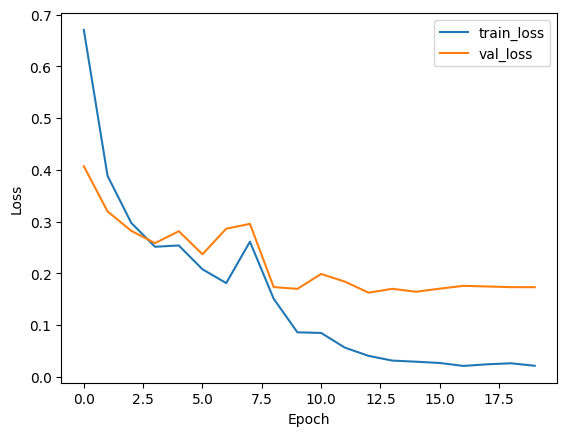

In [75]:
plt.figure()
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()


In [65]:
MODEL_PATH = "best_resnet50.keras"
IMG_SIZE = 224

# IMPORTANT: replace this with EXACT training class_names order
class_names = [
    "Tea algal leaf spot",
    "Brown Blight",
    "Gray Blight",
    "Helopeltis",
    "Red spider",
    "Green mirid bug",
    "Healthy leaf",
]

model = tf.keras.models.load_model(MODEL_PATH)

In [111]:
from PIL import Image
import numpy as np

image_path = r"C:\Users\Lenovo\Desktop\KCGI Academics\Academics\Masters_Project\teaLeafBD_fastCrop_merged\1. Tea algal leaf spot\tea_algal_leaf_spot_00001.jpg"

img = Image.open(image_path).convert("RGB")
img = img.resize((IMG_SIZE, IMG_SIZE))

img_array = np.array(img).astype(np.float32)
img_array = np.expand_dims(img_array, axis=0)

img_array = preprocess_input(img_array)

preds = model.predict(img_array)

pred_idx = np.argmax(preds[0])
confidence = preds[0][pred_idx] * 100

print("Raw prediction index:", pred_idx)
print("Raw class name:", class_names[pred_idx])
print("Confidence:", confidence)
print("All probabilities:")
for i, p in enumerate(preds[0]):
    print(i, class_names[i], round(float(p * 100), 2))

1/1 [==============================] - 0s 271ms/step
Raw prediction index: 5
Raw class name: Green mirid bug
Confidence: 36.515894532203674
All probabilities:
0 Tea algal leaf spot 4.0
1 Brown Blight 7.46
2 Gray Blight 6.25
3 Helopeltis 9.23
4 Red spider 4.8
5 Green mirid bug 36.52
6 Healthy leaf 31.74


In [127]:
for images, labels in test_ds.take(2):
    preds = model.predict(images, verbose=0)

    for i in range(30):
        true_idx = int(labels[i].numpy())
        pred_idx = int(np.argmax(preds[i]))

        print("Real:", class_names[true_idx])
        print("Pred:", class_names[pred_idx])
        print("Conf:", round(float(np.max(preds[i]) * 100), 2))
        print("-" * 40)

Real: Green mirid bug
Pred: Green mirid bug
Conf: 100.0
----------------------------------------
Real: Healthy leaf
Pred: Healthy leaf
Conf: 100.0
----------------------------------------
Real: Healthy leaf
Pred: Healthy leaf
Conf: 100.0
----------------------------------------
Real: Green mirid bug
Pred: Green mirid bug
Conf: 88.93
----------------------------------------
Real: Gray Blight
Pred: Gray Blight
Conf: 99.55
----------------------------------------
Real: Helopeltis
Pred: Helopeltis
Conf: 100.0
----------------------------------------
Real: Gray Blight
Pred: Gray Blight
Conf: 98.28
----------------------------------------
Real: Tea algal leaf spot
Pred: Tea algal leaf spot
Conf: 97.73
----------------------------------------
Real: Green mirid bug
Pred: Green mirid bug
Conf: 98.22
----------------------------------------
Real: Gray Blight
Pred: Gray Blight
Conf: 99.82
----------------------------------------
Real: Green mirid bug
Pred: Green mirid bug
Conf: 100.0
------------

In [153]:
# Pick one image directly from test_df
row = test_df.iloc[2]

image_path = row["path"]
true_idx = int(row["label"])

print("Path:", image_path)
print("True:", class_names[true_idx])

Path: C:\Users\Lenovo\Desktop\KCGI Academics\Academics\Masters_Project\teaLeafBD_fastCrop_merged\4. Helopeltis\helopeltis_00019.jpg
True: Helopeltis


In [155]:
# Single image loader
def load_single_exact(image_path):
    img = tf.io.read_file(image_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32)
    img = preprocess_input(img)
    return tf.expand_dims(img, axis=0)

In [163]:
single_batch = tf.repeat(single_img, repeats=32, axis=0)

single_preds_batch = model(single_batch, training=False).numpy()

single_preds = single_preds_batch[0]

print("Single Pred:", class_names[np.argmax(single_preds)])
print("Single Conf:", round(float(np.max(single_preds) * 100), 2))

Single Pred: Green mirid bug
Single Conf: 52.15


In [159]:
batch_index = 2

for images, labels in test_ds.take(1):
    batch_preds = model(images, training=False).numpy()

    print("Batch true:", class_names[int(labels[batch_index].numpy())])
    print("Batch pred:", class_names[np.argmax(batch_preds[batch_index])])
    print("Batch conf:", round(float(np.max(batch_preds[batch_index]) * 100), 2))

    diff = np.max(
        np.abs(images[batch_index].numpy() - single_img[0].numpy())
    )

    print("Tensor difference:", diff)

Batch true: Helopeltis
Batch pred: Helopeltis
Batch conf: 95.97
Tensor difference: 0.0


In [165]:
import tensorflow as tf
from tensorflow.keras import layers, models

old_model = tf.keras.models.load_model("best_resnet50.keras")

base_model = old_model.get_layer("resnet50")

inputs = layers.Input(shape=(224, 224, 3))

# IMPORTANT: inference mode
x = base_model(inputs, training=False)

# apply the same head layers after resnet50
start = False
for layer in old_model.layers:
    if layer.name == "resnet50":
        start = True
        continue

    if start:
        x = layer(x)

inference_model = models.Model(inputs, x)

inference_model.save("best_resnet50_inference.keras")

In [167]:
model = tf.keras.models.load_model("best_resnet50_inference.keras")

single_preds = model(single_img, training=False).numpy()[0]

print("Single Pred:", class_names[np.argmax(single_preds)])
print("Single Conf:", round(float(np.max(single_preds) * 100), 2))

Single Pred: Helopeltis
Single Conf: 99.46
